In [1]:
# Bước 1 — Văn Nam tự chạy cell này và xác nhận quyền Google Drive.
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from pathlib import Path
ROOT = Path("/content/drive")
FOLDER_IDS = {"E1": "1a-d0mg6HVFAD7YLbdD4jInZwno5eG0t_", "E2": "1IxeYUgEjfuY2x3eMA83OCFgspwOvq3iD", "E3": "1smhryMDPPwx6_YEONRoCi1O3pXOWWqDK"}
for label, fid in FOLDER_IDS.items():
    p = ROOT / ".shortcut-targets-by-id" / fid
    print(label, str(p), "exists:", p.exists())
    if p.exists():
        print([str(x.relative_to(p)) for x in p.rglob("*") if x.is_file()][:100])
print("MyDrive folders:", [x.name for x in (ROOT / "MyDrive").iterdir() if x.is_dir()])

E1 /content/drive/.shortcut-targets-by-id/1a-d0mg6HVFAD7YLbdD4jInZwno5eG0t_ exists: True
['MXH_Output_Ng2/e1_config.json', 'MXH_Output_Ng2/E1_Fox8_Baseline.ipynb', 'MXH_Output_Ng2/honduras_e1_embeddings.csv', 'MXH_Output_Ng2/models/logisticregression.joblib', 'MXH_Output_Ng2/models/randomforest.joblib', 'MXH_Output_Ng2/models/e1_behavioral_encoder.pt', 'MXH_Output_Ng2/models/e1_mlp_full_checkpoint.pt', 'MXH_Output_Ng2/evaluation/e1_metrics.csv', 'MXH_Output_Ng2/evaluation/e1_predictions.csv', 'MXH_Output_Ng2/evaluation/confusion_matrix_logisticregression.png', 'MXH_Output_Ng2/evaluation/confusion_matrix_randomforest.png', 'MXH_Output_Ng2/evaluation/confusion_matrix_mlp.png', 'MXH_Output_Ng2/preprocessing/tfidf_vectorizer.joblib']
E2 /content/drive/.shortcut-targets-by-id/1IxeYUgEjfuY2x3eMA83OCFgspwOvq3iD exists: True
['E2_Output/e2_config.json', 'E2_Output/E2_Honduras_Baseline.ipynb', 'E2_Output/e2_results_report.md', 'E2_Output/E2_Honduras.ipynb', 'E2_Output/evaluation/e2_metrics.csv'

In [3]:
import json, pandas as pd
E1 = ROOT / ".shortcut-targets-by-id" / FOLDER_IDS["E1"] / "MXH_Output_Ng2"
E2 = ROOT / ".shortcut-targets-by-id" / FOLDER_IDS["E2"] / "E2_Output"
BASE = ROOT / ".shortcut-targets-by-id" / FOLDER_IDS["E3"] / "E3_graph_baselines"
for p in [E1/"e1_config.json", E2/"artifacts/e2_config.json", E2/"e2_results_report.md", BASE/"combined/config.json", BASE/"E3_BASELINE_RESULTS.md"]:
    print("FILE", p.name, "\n", p.read_text())
for p in [E2/"artifacts/honduras_e2_scratch_embeddings.csv", E2/"artifacts/honduras_e2_transfer_embeddings.csv", BASE/"combined/nodes.csv", BASE/"combined/edges.csv", BASE/"combined/communities.csv", BASE/"combined/metrics.csv"]:
    df = pd.read_csv(p, nrows=2, dtype=str)
    print("SCHEMA", p.name, list(df.columns), "SAMPLE", df.iloc[:,:6].to_dict("records"))

FILE e1_config.json 
 {
  "experiment": "E1 - Fox8-23 Behavioral Representation Learning",
  "random_seed": 42,
  "device": "cpu",
  "split_file": "fox8_account_splits.csv",
  "split_ratio_expected": {
    "train": 0.7,
    "validation": 0.1,
    "test": 0.2
  },
  "text_preprocessing": {
    "max_tweets_per_account": 30,
    "max_characters_per_account": 5000,
    "lowercase": true,
    "tfidf_ngram_range": [
      1,
      2
    ],
    "tfidf_max_features": 10000,
    "tfidf_min_df": 2
  },
  "models": {
    "LogisticRegression": {
      "max_iter": 2000,
      "class_weight": "balanced"
    },
    "RandomForest": {
      "n_estimators": 200,
      "class_weight": "balanced"
    },
    "MLP": {
      "hidden_dim": 256,
      "embedding_dim": 128,
      "epochs_max": 20,
      "early_stopping_patience": 4,
      "batch_size": 64,
      "learning_rate": 0.001
    }
  },
  "excluded_fields": [
    "dataset"
  ],
  "note": "Input representation is TF-IDF from account tweet text; source-l

In [4]:
for path in [E2/"E2_Honduras.ipynb", BASE/"E3_Graph_Baselines_Nguoi4_Colab.ipynb"]:
    book = json.loads(path.read_text())
    print("NOTEBOOK", path.name)
    for i,c in enumerate(book["cells"]):
        s = "".join(c.get("source", []))
        if c["cell_type"] == "code" and any(t in s for t in (["class ", "embeddings", "train_test", "best_", "load_state", "account_splits", "pos_weight"] if path.name.startswith("E2") else ["def run_leiden", "RBConfiguration", "def graph_metrics", "n_communities", "modularity"])):
            print("CELL", i, s[:18000])

NOTEBOOK E2_Honduras.ipynb
CELL 1 import torch
import torch.nn as nn

# Cấu trúc Encoder (Phải khớp hoàn toàn với E1)
class BehavioralEncoder(nn.Module):
    def __init__(self, input_dim=10000, hidden_dim=256, embedding_dim=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, embedding_dim),
            nn.ReLU(),
        )
    def forward(self, x):
        return self.encoder(x)

# Mô hình phân loại E2 ghép thêm Classification Head
class HondurasBotClassifier(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        # Head phân loại Bad (0) / Good (1)
        self.head = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1) # Binary classification
        )

    def forward(self, x):
        emb = self.encoder(x)

In [5]:
import numpy as np, torch
nodes = pd.read_csv(BASE/"combined/nodes.csv", dtype={"account_id":str})
base_cfg = json.loads((BASE/"combined/config.json").read_text())
embeddings = {}
for name in ["scratch", "transfer"]:
    p = E2/f"artifacts/honduras_e2_{name}_embeddings.csv"
    df = pd.read_csv(p, dtype={"account_id":str})
    cols = [c for c in df if c.startswith("emb_")]
    x = df[cols].to_numpy(dtype=np.float32)
    assert df.account_id.is_unique
    print(name, "shape", x.shape, "finite", np.isfinite(x).all(), "zero_norm", int((np.linalg.norm(x, axis=1)==0).sum()), "in_baseline", df.account_id.isin(nodes.account_id).sum(), "missing_baseline", (~nodes.account_id.isin(df.account_id)).sum())
    embeddings[name] = (df.account_id.to_numpy(), x)
    ck = torch.load(E2/f"artifacts/e2_{name}_model.pt", map_location="cpu", weights_only=True)
    print("checkpoint keys", list(ck)[:15])
    if isinstance(ck,dict):
        for k,v in ck.items():
            if hasattr(v,"shape"): print(k, tuple(v.shape))
print("split counts", nodes["split"].value_counts().to_dict())
print("E2 code sources:")
book = json.loads((E2/"E2_Honduras.ipynb").read_text())
for i in [0,2,3]:
    print("CELL", i, "".join(book["cells"][i].get("source",[])))

scratch shape (44938, 128) finite True zero_norm 0 in_baseline 44938 missing_baseline 179747
checkpoint keys ['encoder.encoder.0.weight', 'encoder.encoder.0.bias', 'encoder.encoder.3.weight', 'encoder.encoder.3.bias', 'head.0.weight', 'head.0.bias', 'head.3.weight', 'head.3.bias']
encoder.encoder.0.weight (256, 10000)
encoder.encoder.0.bias (256,)
encoder.encoder.3.weight (128, 256)
encoder.encoder.3.bias (128,)
head.0.weight (64, 128)
head.0.bias (64,)
head.3.weight (1, 64)
head.3.bias (1,)
transfer shape (44938, 128) finite True zero_norm 0 in_baseline 44938 missing_baseline 179747
checkpoint keys ['encoder.encoder.0.weight', 'encoder.encoder.0.bias', 'encoder.encoder.3.weight', 'encoder.encoder.3.bias', 'head.0.weight', 'head.0.bias', 'head.3.weight', 'head.3.bias']
encoder.encoder.0.weight (256, 10000)
encoder.encoder.0.bias (256,)
encoder.encoder.3.weight (128, 256)
encoder.encoder.3.bias (128,)
head.0.weight (64, 128)
head.0.bias (64,)
head.3.weight (1, 64)
head.3.bias (1,)
split

In [6]:
print("Embedding split audit")
for name,(ids,x) in embeddings.items():
    print(name, nodes.set_index("account_id").loc[ids,"split"].value_counts().to_dict())
print("Data paths declared in baseline notebook")
book=json.loads((BASE/"E3_Graph_Baselines_Nguoi4_Colab.ipynb").read_text())
for c in book["cells"]:
    s="".join(c.get("source",[]))
    if c["cell_type"]=="code" and "DATA =" in s: print(s[:12000])
p=ROOT/"MyDrive/Colab Notebooks"
print("Colab folders", [x.name for x in p.iterdir() if x.is_dir()])

Embedding split audit
scratch {'test': 44938}
transfer {'test': 44938}
Data paths declared in baseline notebook
# E3 — 2. Cấu hình và kiểm tra input
%pip install -q igraph leidenalg

from pathlib import Path
import json, hashlib, sys, platform, unicodedata, math
from collections import Counter, defaultdict
from itertools import combinations

import pandas as pd
import networkx as nx
import igraph as ig
import leidenalg

from IPython.display import display


# ============================================================
# ĐƯỜNG DẪN
# ============================================================

# Folder MXH là shortcut đã thêm vào My Drive
BASE = Path('/content/drive/MyDrive')

# Dữ liệu shared nằm trong MXH/processed
DATA = BASE / 'MXH' / 'processed'

# Output của E3 lưu riêng trong My Drive
OUT = BASE / 'E3_outputs'


# ============================================================
# CONFIG E3
# ============================================================

SEED = 42

RESOLUTION = 1.0

#

In [7]:
for p in [ROOT/"MyDrive/MXH/processed", ROOT/"MyDrive/Colab Notebooks/MXH_4_output"]:
    print("PATH",p,"exists",p.exists())
    if p.exists(): print([str(x.relative_to(p)) for x in p.iterdir()])
print("Shared roots:", [x.name for x in (ROOT/".shortcut-targets-by-id").iterdir()])

PATH /content/drive/MyDrive/MXH/processed exists False
PATH /content/drive/MyDrive/Colab Notebooks/MXH_4_output exists True
['MXH', 'E3_outputs', 'E3_Coordination_Graph.ipynb']
Shared roots: ['1smhryMDPPwx6_YEONRoCi1O3pXOWWqDK', '1a-d0mg6HVFAD7YLbdD4jInZwno5eG0t_', '1IxeYUgEjfuY2x3eMA83OCFgspwOvq3iD']


In [8]:
DATA = ROOT/"MyDrive/Colab Notebooks/MXH_4_output/MXH/processed"
print("processed exists",DATA.exists())
if DATA.exists():
    print([x.name for x in DATA.iterdir()])

processed exists True
['honduras_bad_normalized.jsonl', 'honduras_good_normalized.jsonl', 'quality_audit', 'honduras_account_splits.csv', 'fox8_account_manifest.csv', 'fox8_account_splits.csv', 'fox8_train_ids.csv', 'fox8_test_ids.csv', 'honduras_validation_ids.csv', 'honduras_train_ids.csv', 'fox8_validation_ids.csv', 'honduras_test_ids.csv', 'honduras_account_manifest.csv']


In [9]:
import joblib
from collections import defaultdict
texts=defaultdict(list)
for p in [DATA/"honduras_bad_normalized.jsonl",DATA/"honduras_good_normalized.jsonl"]:
    with p.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip(): continue
            r=json.loads(line); uid=str(r["account_id"]); text=r.get("text")
            if isinstance(text,str) and text.strip() and len(texts[uid])<30: texts[uid].append(text.strip())
vectorizer=joblib.load(E1/"preprocessing/tfidf_vectorizer.joblib")
import torch.nn as nn
class BehavioralEncoder(nn.Module):
    def __init__(self):
        super().__init__(); self.encoder=nn.Sequential(nn.Linear(10000,256),nn.ReLU(),nn.Dropout(0.3),nn.Linear(256,128),nn.ReLU())
    def forward(self,x): return self.encoder(x)
models={}
for name in ["scratch","transfer"]:
    ck=torch.load(E2/f"artifacts/e2_{name}_model.pt",map_location="cpu",weights_only=True)
    model=BehavioralEncoder()
    model.load_state_dict({k[len("encoder."):]:v for k,v in ck.items() if k.startswith("encoder.")})
    model.eval(); models[name]=model
    ids, expected=embeddings[name]; chosen=np.arange(min(256,len(ids)))
    sparse=vectorizer.transform([" ".join(texts.get(u,[]))[:5000] for u in ids[chosen]])
    with torch.inference_mode(): actual=model(torch.from_numpy(sparse.toarray().astype(np.float32))).numpy()
    print(name,"reproduction sample",len(chosen),"max_abs_error",float(np.max(np.abs(actual-expected[chosen]))),"matches",np.allclose(actual,expected[chosen],atol=1e-4,rtol=1e-4))
print("accounts with text", len(texts))

scratch reproduction sample 256 max_abs_error 1.430511474609375e-06 matches True
transfer reproduction sample 256 max_abs_error 1.430511474609375e-06 matches True
accounts with text 224685


In [10]:
# E3-N5 — Tạo full-corpus embeddings bằng checkpoint E2 đã bàn giao
import time, hashlib, importlib.metadata as metadata
OUT = ROOT/"MyDrive/Colab Notebooks/E3_proposed_outputs"
OUT.mkdir(parents=True, exist_ok=True)
ids_all = nodes.account_id.to_numpy()
X = vectorizer.transform([" ".join(texts.get(u,[]))[:5000] for u in ids_all]).tocsr()
input_valid = np.diff(X.indptr)>0
np.save(OUT/"input_has_tfidf_signal.npy", input_valid)
print("TF-IDF shape",X.shape,"zero-input accounts",int((~input_valid).sum()),flush=True)
full_embeddings={}
reproduction={}
torch.set_num_threads(2)
INFERENCE_DEVICE=torch.device("cpu")
print("Embedding inference device:",INFERENCE_DEVICE,flush=True)
for name,model in models.items():
    model=model.to(INFERENCE_DEVICE).eval()
    started=time.time(); z=np.empty((len(ids_all),128),dtype=np.float32)
    with torch.inference_mode():
        for start in range(0,len(ids_all),512):
            z[start:start+512]=model(torch.from_numpy(X[start:start+512].toarray().astype(np.float32)).to(INFERENCE_DEVICE)).cpu().numpy()
    assert np.isfinite(z).all()
    existing_ids,expected=embeddings[name]
    positions=pd.Index(ids_all).get_indexer(existing_ids)
    delta=float(np.max(np.abs(z[positions]-expected)))
    ok=bool(np.allclose(z[positions],expected,atol=1e-4,rtol=1e-4))
    reproduction[name]={"n_compared":len(positions),"max_abs_error":delta,"allclose":ok}
    print(name,reproduction[name],"seconds",round(time.time()-started,1),flush=True)
    assert ok, "Preprocessing không tái tạo được output E2; dừng trước khi tạo graph."
    full_embeddings[name]=z
    np.save(OUT/f"{name}_embeddings.npy",z)
pd.DataFrame({"account_id":ids_all,"has_tfidf_signal":input_valid}).to_csv(OUT/"embedding_account_ids.csv",index=False)
(OUT/"embedding_reproduction.json").write_text(json.dumps(reproduction,indent=2))
print("PASS: full embeddings saved",OUT)

TF-IDF shape (224685, 10000) zero-input accounts 50
Embedding inference device: cpu
scratch {'n_compared': 44938, 'max_abs_error': 1.049041748046875e-05, 'allclose': True} seconds 31.0
transfer {'n_compared': 44938, 'max_abs_error': 8.58306884765625e-06, 'allclose': True} seconds 34.8
PASS: full embeddings saved /content/drive/MyDrive/Colab Notebooks/E3_proposed_outputs


In [11]:
# CPU setup — protocol tương thích bản bàn giao người 4
%pip -q install faiss-cpu igraph leidenalg
import numpy as np, pandas as pd, json
import faiss, igraph as ig, leidenalg
from scipy import sparse
from scipy.sparse import coo_matrix
CFG={"lambda":0.5,"top_k":5,"cosine_threshold":0.9,"seed":42,"resolution":1.0,
     "leiden_iterations":-1,"efConstruction":80,"efSearch":128,
     "backend":"igraph_leidenalg_cpu",
     "ann":"FAISS HNSW32 inner product on L2-normalized vectors",
     "symmetrization":"union directed top-k, weight=max cosine",
     "baseline_normalization":"divide by positive undirected edge-weight sum"}
faiss.omp_set_num_threads(1)
print("CPU Leiden ready: RBConfigurationVertexPartition, seed=42, resolution=1, iterations=-1.")


CPU Leiden ready: RBConfigurationVertexPartition, seed=42, resolution=1, iterations=-1.


In [12]:
# E3-N5 — Đọc baseline, kiểm tra trọng số/node và chuẩn hóa input similarity
from scipy.sparse import coo_matrix
from sklearn.metrics import adjusted_rand_score
assert nodes.account_id.is_unique and nodes.account_id.tolist()==sorted(nodes.account_id)
idx=pd.Index(ids_all)
base_edges=pd.read_csv(BASE/"combined/edges.csv",dtype={"source":str,"target":str})
u=idx.get_indexer(base_edges.source); v=idx.get_indexer(base_edges.target)
w=base_edges.weight.to_numpy(dtype=np.float64)
assert (u>=0).all() and (v>=0).all() and (u<v).all()
assert np.isfinite(w).all() and (w>0).all() and (w<=1+1e-9).all()
assert not base_edges.duplicated(["source","target"]).any()
B=coo_matrix((w,(u,v)),shape=(len(nodes),len(nodes))).tocsr()
base_metrics=pd.read_csv(BASE/"combined/metrics.csv").iloc[0].to_dict()
assert B.nnz==int(base_metrics["n_edges"])
assert len(nodes)==int(base_metrics["n_nodes"])
print("PASS baseline:",len(nodes),"nodes",B.nnz,"edges")
def similarity_graph(name,z):
    valid=input_valid & np.isfinite(z).all(axis=1) & (np.linalg.norm(z,axis=1)>0)
    positions=np.flatnonzero(valid); features=np.ascontiguousarray(z[valid].copy())
    faiss.normalize_L2(features)
    index=faiss.IndexHNSWFlat(features.shape[1],32,faiss.METRIC_INNER_PRODUCT)
    index.hnsw.efConstruction=CFG["efConstruction"]; index.hnsw.efSearch=CFG["efSearch"]
    index.add(features)
    print(name,"ANN indexed",len(positions),flush=True)
    srcs=[]; dsts=[]; scores=[]; k=min(CFG["top_k"]+1,len(positions))
    for start in range(0,len(positions),4096):
        d,j=index.search(features[start:start+4096],k)
        for offset in range(len(d)):
            local=start+offset
            candidates=[(float(np.clip(score,-1,1)),int(target)) for score,target in zip(d[offset],j[offset]) if target>=0 and target!=local and score>max(0,CFG["cosine_threshold"])]
            candidates.sort(key=lambda a:(-a[0],int(positions[a[1]])))
            for score,target in candidates[:CFG["top_k"]]:
                srcs.append(int(positions[local])); dsts.append(int(positions[target])); scores.append(score)
    directed=coo_matrix((scores,(srcs,dsts)),shape=B.shape).tocsr()
    upper=sparse.triu(directed.maximum(directed.T),k=1,format="csr")
    assert (upper.data>CFG["cosine_threshold"]).all()
    # Label-free ANN diagnostic: exact score of true kth neighbor on fixed sample.
    rng=np.random.default_rng(CFG["seed"]); sample=rng.choice(len(features),min(128,len(features)),replace=False)
    exact=faiss.IndexFlatIP(features.shape[1]); exact.add(features)
    ed,ej=exact.search(features[sample],k); ad,aj=index.search(features[sample],k)
    recalls=[]; score_success=[]
    for q,truth,td,pred,pd_ in zip(sample,ej,ed,aj,ad):
        truth=[int(t) for t in truth if t!=q][:CFG["top_k"]]
        got=[int(t) for t in pred if t!=q][:CFG["top_k"]]
        recalls.append(len(set(truth)&set(got))/max(1,len(truth)))
        truth_scores=[float(s) for t,s in zip(ej[np.where(sample==q)[0][0]],td) if t!=q][:CFG["top_k"]]
        got_scores=[float(s) for t,s in zip(pred,pd_) if t!=q][:CFG["top_k"]]
        score_success.append(bool(len(got_scores)==len(truth_scores) and (not truth_scores or min(got_scores)>=min(truth_scores)-1e-5)))
    audit={"method":name,"n_accounts":len(nodes),"n_valid_embedding_accounts":int(valid.sum()),"embedding_coverage":float(valid.mean()),"n_similarity_edges":int(upper.nnz),"ann_sample_size":len(sample),"ann_id_recall_at_k":float(np.mean(recalls)),"ann_kth_score_success_rate":float(np.mean(score_success)),"ann_note":"ID recall can be low with tied/identical vectors; score agreement is reported separately."}
    print(audit,flush=True)
    return upper,audit

PASS baseline: 224685 nodes 1922134 edges


In [13]:
# E3-N5 — Pilot chọn tham số: quy tắc công bố trước khi xem bảng kết quả
# Không đọc label hoặc dùng kết quả Test để xếp hạng cấu hình.
# 1) Chọn threshold lớn nhất trong {0.7,0.8,0.9} có >=90% valid Validation nodes có cạnh, ở CẢ HAI encoder.
# 2) Chọn k nhỏ nhất trong {5,10,20} giữ >=95% LCC coverage của k=20 ở CẢ HAI encoder.
# 3) lambda=0.5 là lựa chọn thiết kế cân bằng total edge-weight mass; không tối ưu theo nhãn/modularity.
# Không có ground truth campaign: các tiêu chí này chỉ kiểm soát coverage, sparsity và scale.
PILOT=ROOT/"MyDrive/Colab Notebooks/E3_proposed_outputs/parameter_selection"; PILOT.mkdir(exist_ok=True)
PILOT_RULE={"split":"validation","seed":42,"threshold_candidates":[0.7,0.8,0.9],"k_candidates":[5,10,20],"minimum_valid_node_coverage":0.9,"minimum_lcc_retention_vs_k20":0.95,"threshold_rule":"largest passing threshold for both encoders","k_rule":"smallest passing k for both encoders","lambda":0.5,"lambda_reason":"equal total weight contribution after each graph is normalized by its positive undirected edge-weight sum","labels_used":False,"test_metrics_used":False,"status":"design_criteria_not_campaign_accuracy_optimization"}
(PILOT/"selection_rule.json").write_text(json.dumps(PILOT_RULE,ensure_ascii=False,indent=2))
vp=np.flatnonzero((nodes["split"].to_numpy()=="validation") & input_valid)
print("Pilot Validation valid accounts",len(vp),flush=True)
faiss.omp_set_num_threads(2)
pilot_rows=[]; pilot_matrices={}
for name,z in full_embeddings.items():
    f=np.ascontiguousarray(z[vp].copy()); faiss.normalize_L2(f)
    exact=faiss.IndexFlatIP(f.shape[1]); exact.add(f)
    scores,neighbors=exact.search(f,21)
    for threshold in PILOT_RULE["threshold_candidates"]:
        for k in PILOT_RULE["k_candidates"]:
            aa=[]; bb=[]; ww=[]
            for q,(ds,js) in enumerate(zip(scores,neighbors)):
                candidates=sorted([(float(np.clip(d,-1,1)),int(j)) for d,j in zip(ds,js) if j>=0 and j!=q and d>threshold],key=lambda p:(-p[0],p[1]))[:k]
                for d,j in candidates: aa.append(q); bb.append(j); ww.append(d)
            dmat=coo_matrix((ww,(aa,bb)),shape=(len(vp),len(vp))).tocsr()
            upper=sparse.triu(dmat.maximum(dmat.T),k=1,format="csr")
            adj=upper+upper.T
            degree=np.diff(adj.indptr); nc,labels_cc=sparse.csgraph.connected_components(adj,directed=False)
            lcc=int(np.bincount(labels_cc).max())
            row={"method":name,"threshold":threshold,"top_k":k,"n_nodes":len(vp),"n_edges":int(upper.nnz),"active_coverage":float((degree>0).mean()),"lcc_fraction":lcc/len(vp),"median_degree":float(np.median(degree)),"max_degree":int(degree.max()),"weight_sum":float(upper.sum())}
            pilot_rows.append(row); pilot_matrices[(name,threshold,k)]=upper
    print(name,"exact pilot complete",flush=True)
pilot_df=pd.DataFrame(pilot_rows)
pilot_df.to_csv(PILOT/"validation_grid.csv",index=False)
passed=[]
for threshold in PILOT_RULE["threshold_candidates"]:
    ref=pilot_df[(pilot_df.threshold==threshold)&(pilot_df.top_k==20)]
    if (ref.active_coverage>=0.9).all(): passed.append(threshold)
assert passed,"Không có threshold đạt coverage; cần xem phân bố cosine trước khi chốt."
chosen_threshold=max(passed)
chosen_k=None
for k in PILOT_RULE["k_candidates"]:
    candidate=pilot_df[(pilot_df.threshold==chosen_threshold)&(pilot_df.top_k==k)].set_index("method")
    reference=pilot_df[(pilot_df.threshold==chosen_threshold)&(pilot_df.top_k==20)].set_index("method")
    if (candidate.active_coverage>=0.9).all() and (candidate.lcc_fraction>=0.95*reference.lcc_fraction).all():
        chosen_k=k; break
assert chosen_k is not None
print("CHOSEN",{"threshold":chosen_threshold,"top_k":chosen_k,"lambda":0.5},flush=True)
display(pilot_df)

Pilot Validation valid accounts 22465
scratch exact pilot complete
transfer exact pilot complete
CHOSEN {'threshold': 0.9, 'top_k': 5, 'lambda': 0.5}


,method,threshold,top_k,n_nodes,n_edges,active_coverage,lcc_fraction,median_degree,max_degree,weight_sum
0,scratch,0.7,5,22465,87238,1.0,0.945426,6.0,136,87206.485933
1,scratch,0.7,10,22465,169792,1.0,0.980637,13.0,246,169717.182624
2,scratch,0.7,20,22465,331206,1.0,0.990430,26.0,256,331023.583302
3,scratch,0.8,5,22465,87238,1.0,0.945426,6.0,136,87206.485933
4,scratch,0.8,10,22465,169792,1.0,0.980637,13.0,246,169717.182624
5,scratch,0.8,20,22465,331206,1.0,0.990430,26.0,256,331023.583302
6,scratch,0.9,5,22465,87238,1.0,0.945426,6.0,136,87206.485933
7,scratch,0.9,10,22465,169792,1.0,0.980637,13.0,246,169717.182624
8,scratch,0.9,20,22465,331206,1.0,0.990430,26.0,256,331023.583302
9,transfer,0.7,5,22465,84066,1.0,0.967371,6.0,236,84028.163212


In [ ]:
# E3-N5 — Quyết định tham số và lý do, dựa trên Validation pilot
ROOT_OUT=ROOT/"MyDrive/Colab Notebooks/E3_proposed_outputs"
PILOT=ROOT_OUT/"parameter_selection"
selected={"lambda":0.5,"top_k":int(chosen_k),"cosine_threshold":float(chosen_threshold),"status":"selected_on_validation_structure_with_neutral_lambda_design","weight_normalization":"each undirected graph divided by its total positive edge-weight sum","selection_artifact":str(PILOT/"PARAMETER_SELECTION.md"),"selection_uses_labels":False,"scope":"full_corpus_descriptive_transductive"}
(PILOT/"chosen_config.json").write_text(json.dumps(selected,ensure_ascii=False,indent=2))
reference=pilot_df[(pilot_df.threshold==chosen_threshold)&(pilot_df.top_k==20)].set_index("method")
chosen=pilot_df[(pilot_df.threshold==chosen_threshold)&(pilot_df.top_k==chosen_k)].copy()
chosen["lcc_retention_vs_k20"]=[r.lcc_fraction/reference.loc[r.method,"lcc_fraction"] for r in chosen.itertuples()]
chosen["edge_reduction_vs_k20"]=[1-r.n_edges/reference.loc[r.method,"n_edges"] for r in chosen.itertuples()]
bpilot=B[vp][:,vp]; base_mass=float(bpilot.sum())
assert base_mass>0
mass_rows=[]
for name in ["scratch","transfer"]:
    sm=pilot_matrices[(name,chosen_threshold,chosen_k)]
    sim_mass=float(sm.sum())
    mass_rows.append({"method":name,"validation_baseline_weight_sum":base_mass,"validation_similarity_weight_sum":sim_mass,"similarity_mass_fraction_without_calibration_at_lambda_05":sim_mass/(base_mass+sim_mass),"similarity_mass_fraction_after_sum_normalization_at_lambda_05":0.5})
mass_df=pd.DataFrame(mass_rows)
chosen.to_csv(PILOT/"selected_validation_metrics.csv",index=False)
mass_df.to_csv(PILOT/"weight_scale_audit.csv",index=False)
parts=[
"# E3 — Quyết định λ, top-k và cosine threshold",
"Quyết định: λ=0.5, top-k=5, cosine threshold=0.9, dùng chung cho Scratch và Transfer.",
"## 1. Mục tiêu và dữ liệu",
"Chọn graph thưa, giữ độ phủ và khả năng liên thông; không tối ưu độ chính xác campaign vì không có campaign ground truth. Dùng 22.468 account Validation cố định, trong đó 22.465 có tín hiệu TF-IDF. Ba account không có tín hiệu vẫn giữ ở graph chính, không tạo similarity từ bias-only embedding. Không đọc nhãn Bad/Good hoặc dùng kết quả Test để xếp hạng cấu hình.",
"Lượt pilot thực hiện sau lượt thăm dò full corpus với 0.5/10/0.8. Quy tắc lựa chọn được ghi vào selection_rule.json trước khi chạy bảng pilot; đây không phải preregistration trước toàn bộ nghiên cứu.",
"## 2. Lưới và quy tắc đã khai báo trước pilot",
"Thử threshold={0.7,0.8,0.9}, k={5,10,20}: 9 cấu hình/encoder, 18 dòng kết quả. L2-normalize embedding; dùng exact cosine search trên Validation, bỏ self-loop, đối xứng union/max. Với nhiều neighbor đồng điểm, exact search có thể trả một tập tied candidates; không coi ID của chúng là duy nhất.",
"Chọn threshold lớn nhất có ít nhất 90% valid nodes có cạnh ở cả hai encoder. Sau đó chọn k nhỏ nhất vẫn phủ ít nhất 90% valid nodes và giữ ít nhất 95% LCC coverage so với k=20, ở cả hai encoder. Các mức 90%/95% là ràng buộc thiết kế được công bố trước lượt pilot, không phải ngưỡng phổ quát của coordination detection.",
"## 3. Lý do threshold=0.9",
"Cả ba threshold đều đạt yêu cầu. Chọn 0.9 vì đây là mức nghiêm ngặt nhất trong lưới vẫn đạt độ phủ. Tuy nhiên, các top-neighbor cosine rất cao nên threshold 0.7–0.9 hầu như không thay đổi graph. Không kết luận 0.9 là ngưỡng ngữ nghĩa tối ưu hoặc bằng chứng phối hợp.",
"## 4. Lý do top-k=5",
"k=5 đã đạt ràng buộc LCC retention ở cả hai encoder và vẫn giữ 100% valid-node coverage. Chọn mức nhỏ nhất đạt yêu cầu để giảm số cạnh và chi phí so với k=10/20. Sau đối xứng hóa, degree có thể lớn hơn 5; k chỉ giới hạn lựa chọn láng giềng có hướng trước union.",
chosen.to_markdown(index=False),
"## 5. Lý do lambda=0.5 và thay đổi quy ước scale",
"Không có cơ sở độc lập để ưu tiên baseline hay similarity theo chất lượng campaign. Chọn lambda=0.5 là thiết kế trung lập về tổng trọng số, không phải giá trị được chứng minh tối ưu. Không dùng modularity hoặc Bad Ratio trên full corpus để chọn lambda.",
"Trước khi trộn, chuẩn hóa riêng từng graph bằng tổng trọng số cạnh vô hướng dương:",
"W_base_hat = W_base / sum_{u<v} W_base[u,v]",
"W_sim_hat = W_sim / sum_{u<v} W_sim[u,v]",
"W_enhanced = (1-lambda)*W_base_hat + lambda*W_sim_hat.",
"Chỉ scale trọng số, không thay topology baseline. Nếu một nguồn có tổng trọng số bằng 0, dừng và báo lỗi thay vì chia 0 hoặc âm thầm đổi công thức. Với lambda=0.5, mỗi nguồn đóng góp một nửa tổng trọng số trước khi cộng cạnh trùng. Không có nghĩa là mỗi nguồn đóng góp một nửa chất lượng phát hiện.",
"Giữ trọng số baseline chưa hiệu chuẩn rồi trộn với cosine gần 1 sẽ khiến similarity chi phối, dù cả hai đều nằm trong [0,1]. Audit trên Validation:",
mass_df.to_markdown(index=False),
"## 6. Áp dụng và trạng thái",
"Dùng cùng λ/k/threshold, chuẩn hóa tổng trọng số và Leiden seed=42, resolution=1, RBConfigurationVertexPartition, iterations=-1 cho cả hai graph tăng cường. Scope chính giữ full corpus, mô tả/transductive, cùng node set với người 4. Full-corpus ANN cần được audit riêng; pilot exact search không chứng minh ANN full-corpus là chính xác.",
"Thay đổi cả k/threshold và weight normalization so với lượt thăm dò cũ. Không đổi tên output cũ thành kết quả cấu hình mới. Cần chạy lại hai graph và Leiden với cấu hình đã chọn; lưu tại results/. Lượt thăm dò chưa hoàn tất đã được ngắt, embedding và baseline kiểm tra vẫn được giữ.",
"## 7. Giới hạn và sensitivity",
"Tiêu chí trên chọn sparsity/coverage, không xác nhận semantic coordination, bot hay malicious campaign. Cosine gần 1 và nhiều tied neighbors cần được nêu rõ. Chưa chạy sensitivity của lambda=0.25/0.75, edge-count control hay kiểm định community stability; không ghi các phân tích này là đã hoàn tất.",
"Vấn đề pos_weight và validation checkpoint của E2 vẫn cần người 3 xác minh. Tham số graph này không sửa được hạn chế của checkpoint đầu vào.",
"## Tái chạy",
"Chạy cell pilot rồi cell quyết định này trước cell tạo graph chính. Có thể đọc toàn bộ 18 cấu hình từ validation_grid.csv; config chính nằm ở chosen_config.json."
]
decision_text=(chr(10)*2).join(parts)
(PILOT/"PARAMETER_SELECTION.md").write_text(decision_text,encoding="utf-8")
CFG.update(selected)
print("CHỐT:",selected)
display(chosen)
display(mass_df)
print("SAVED",PILOT/"PARAMETER_SELECTION.md")


CHỐT: {'lambda': 0.5, 'top_k': 5, 'cosine_threshold': 0.9, 'status': 'selected_on_validation_structure_with_neutral_lambda_design', 'weight_normalization': 'each undirected graph divided by its total positive edge-weight sum', 'selection_artifact': '/content/drive/MyDrive/Colab Notebooks/E3_proposed_outputs/parameter_selection/PARAMETER_SELECTION.md', 'selection_uses_labels': False, 'scope': 'full_corpus_descriptive_transductive'}


,method,threshold,top_k,n_nodes,n_edges,active_coverage,lcc_fraction,median_degree,max_degree,weight_sum,lcc_retention_vs_k20,edge_reduction_vs_k20
6,scratch,0.9,5,22465,87238,1.0,0.945426,6.0,136,87206.485933,0.954562,0.736605
15,transfer,0.9,5,22465,84062,1.0,0.967371,6.0,236,84024.976162,0.967371,0.733411


,method,validation_baseline_weight_sum,validation_similarity_weight_sum,similarity_mass_fraction_without_calibration_at_lambda_05,similarity_mass_fraction_after_sum_normalization_at_lambda_05
0,scratch,12.886711,87206.485933,0.999852,0.5
1,transfer,12.886711,84024.976162,0.999847,0.5


SAVED /content/drive/MyDrive/Colab Notebooks/E3_proposed_outputs/parameter_selection/PARAMETER_SELECTION.md


In [ ]:
# CPU fast path — dùng cache đã lưu; chạy sau cell CPU setup và mount Drive.
from pathlib import Path
import time, hashlib, json, importlib.metadata as metadata
import numpy as np, pandas as pd
from scipy import sparse
from scipy.sparse import coo_matrix
from sklearn.metrics import adjusted_rand_score
from IPython.display import display
import igraph as ig, leidenalg, faiss
ROOT=Path("/content/drive")
CACHE=ROOT/"MyDrive/Colab Notebooks/E3_proposed_outputs"
BASE=ROOT/".shortcut-targets-by-id/1smhryMDPPwx6_YEONRoCi1O3pXOWWqDK/E3_graph_baselines"
E1=ROOT/".shortcut-targets-by-id/1a-d0mg6HVFAD7YLbdD4jInZwno5eG0t_/MXH_Output_Ng2"
E2=ROOT/".shortcut-targets-by-id/1IxeYUgEjfuY2x3eMA83OCFgspwOvq3iD/E2_Output"
DATA=ROOT/"MyDrive/Colab Notebooks/MXH_4_output/MXH/processed"
assert (CACHE/"scratch_embeddings.npy").is_file(), "Mount Drive và kiểm tra embedding cache."
base_cfg=json.loads((BASE/"combined/config.json").read_text())
CFG=dict(seed=int(base_cfg["seed"]),resolution=float(base_cfg["resolution"]),leiden_iterations=int(base_cfg["leiden_iterations"]),
         efConstruction=80,efSearch=128,backend="igraph_leidenalg_cpu",ann="FAISS HNSW32 CPU")
nodes=pd.read_csv(BASE/"combined/nodes.csv",dtype={"account_id":str})
ids_all=nodes.account_id.to_numpy()
cache_ids=pd.read_csv(CACHE/"embedding_account_ids.csv",dtype={"account_id":str})
assert nodes.account_id.is_unique and cache_ids.account_id.tolist()==ids_all.tolist()
input_valid=np.load(CACHE/"input_has_tfidf_signal.npy")
full_embeddings={n:np.load(CACHE/f"{n}_embeddings.npy",mmap_mode="r") for n in ["scratch","transfer"]}
reproduction=json.loads((CACHE/"embedding_reproduction.json").read_text())
decision_text=(CACHE/"parameter_selection/PARAMETER_SELECTION.md").read_text()
base_metrics=pd.read_csv(BASE/"combined/metrics.csv").iloc[0].to_dict()
base_edges=pd.read_csv(BASE/"combined/edges.csv",dtype={"source":str,"target":str})
ix=pd.Index(ids_all)
u=ix.get_indexer(base_edges.source); v=ix.get_indexer(base_edges.target)
w=base_edges.weight.to_numpy(dtype=np.float64)
assert (u>=0).all() and (v>=0).all() and (u<v).all() and (w>0).all() and np.isfinite(w).all()
B=coo_matrix((w,(u,v)),shape=(len(nodes),len(nodes))).tocsr()
assert B.nnz==int(base_metrics["n_edges"])
faiss.omp_set_num_threads(1)

def similarity_graph(name,z):
    valid=input_valid & np.isfinite(z).all(axis=1) & (np.linalg.norm(z,axis=1)>0)
    positions=np.flatnonzero(valid); features=np.ascontiguousarray(z[valid].copy())
    faiss.normalize_L2(features)
    index=faiss.IndexHNSWFlat(features.shape[1],32,faiss.METRIC_INNER_PRODUCT)
    index.hnsw.efConstruction=CFG["efConstruction"]; index.hnsw.efSearch=CFG["efSearch"]
    index.add(features)
    print(name,"ANN indexed",len(positions),flush=True)
    srcs=[]; dsts=[]; scores=[]; k=min(CFG["top_k"]+1,len(positions))
    for start in range(0,len(positions),4096):
        d,j=index.search(features[start:start+4096],k)
        for offset in range(len(d)):
            local=start+offset
            candidates=[(float(np.clip(score,-1,1)),int(target)) for score,target in zip(d[offset],j[offset]) if target>=0 and target!=local and score>max(0,CFG["cosine_threshold"])]
            candidates.sort(key=lambda a:(-a[0],int(positions[a[1]])))
            for score,target in candidates[:CFG["top_k"]]:
                srcs.append(int(positions[local])); dsts.append(int(positions[target])); scores.append(score)
    directed=coo_matrix((scores,(srcs,dsts)),shape=B.shape).tocsr()
    upper=sparse.triu(directed.maximum(directed.T),k=1,format="csr")
    assert (upper.data>CFG["cosine_threshold"]).all()
    # Label-free ANN diagnostic: exact score of true kth neighbor on fixed sample.
    rng=np.random.default_rng(CFG["seed"]); sample=rng.choice(len(features),min(128,len(features)),replace=False)
    exact=faiss.IndexFlatIP(features.shape[1]); exact.add(features)
    ed,ej=exact.search(features[sample],k); ad,aj=index.search(features[sample],k)
    recalls=[]; score_success=[]
    for q,truth,td,pred,pd_ in zip(sample,ej,ed,aj,ad):
        truth=[int(t) for t in truth if t!=q][:CFG["top_k"]]
        got=[int(t) for t in pred if t!=q][:CFG["top_k"]]
        recalls.append(len(set(truth)&set(got))/max(1,len(truth)))
        truth_scores=[float(s) for t,s in zip(ej[np.where(sample==q)[0][0]],td) if t!=q][:CFG["top_k"]]
        got_scores=[float(s) for t,s in zip(pred,pd_) if t!=q][:CFG["top_k"]]
        score_success.append(bool(len(got_scores)==len(truth_scores) and (not truth_scores or min(got_scores)>=min(truth_scores)-1e-5)))
    audit={"method":name,"n_accounts":len(nodes),"n_valid_embedding_accounts":int(valid.sum()),"embedding_coverage":float(valid.mean()),"n_similarity_edges":int(upper.nnz),"ann_sample_size":len(sample),"ann_id_recall_at_k":float(np.mean(recalls)),"ann_kth_score_success_rate":float(np.mean(score_success)),"ann_note":"ID recall can be low with tied/identical vectors; score agreement is reported separately."}
    print(audit,flush=True)
    return upper,audit
# Selected configuration must be generated by the Validation pilot above before this cell is run.
selection_path=ROOT/"MyDrive/Colab Notebooks/E3_proposed_outputs/parameter_selection/chosen_config.json"
assert selection_path.is_file(), "Run the Validation pilot and decision cells first."
CFG.update(json.loads(selection_path.read_text()))
CFG["baseline_normalization"]="divide by positive undirected edge-weight sum"
faiss.omp_set_num_threads(1)
OUT=ROOT/"MyDrive/Colab Notebooks/E3_proposed_outputs/results"
OUT.mkdir(exist_ok=True)
# E3-N5 — Leiden cùng protocol baseline; export graph và metrics
def save_edges(matrix,path):
    co=matrix.tocoo(); order=np.lexsort((co.col,co.row))
    pd.DataFrame({"source":ids_all[co.row[order]],"target":ids_all[co.col[order]],"weight":co.data[order]}).to_csv(path,index=False)
def evaluate_graph(name,matrix,extra=None):
    folder=OUT/name; folder.mkdir(exist_ok=True)
    co=matrix.tocoo(); order=np.lexsort((co.col,co.row)); a=co.row[order]; b=co.col[order]; weight=co.data[order]
    assert (a<b).all() and np.isfinite(weight).all() and (weight>0).all()
    active=np.unique(np.concatenate([a,b])); mapping=np.full(len(nodes),-1,dtype=np.int64); mapping[active]=np.arange(len(active))
    graph=ig.Graph(n=len(active),edges=np.column_stack([mapping[a],mapping[b]]),directed=False)
    graph.es["weight"]=weight.tolist()
    part=leidenalg.find_partition(graph,leidenalg.RBConfigurationVertexPartition,weights="weight",resolution_parameter=CFG["resolution"],n_iterations=CFG["leiden_iterations"],seed=CFG["seed"])
    groups=sorted([np.sort(active[np.asarray(group,dtype=int)]) for group in part],key=lambda g:(-len(g),int(g[0])))
    membership=np.full(len(nodes),-1,dtype=int)
    for c,group in enumerate(groups): membership[group]=c
    degree=np.zeros(len(nodes),dtype=int); degree[active]=graph.degree()
    strength=np.zeros(len(nodes)); strength[active]=graph.strength(weights="weight")
    assert degree.sum()==2*matrix.nnz
    components=graph.connected_components(); sizes=components.sizes(); cs=[len(g) for g in groups]
    row={"method":name,"scope":CFG["scope"],"status":CFG["status"],"seed":CFG["seed"],"resolution":CFG["resolution"],"n_nodes":len(nodes),"n_active_nodes":len(active),"n_edges":int(matrix.nnz),"density":2*matrix.nnz/(len(nodes)*(len(nodes)-1)),"n_isolates":len(nodes)-len(active),"isolated_node_rate":1-len(active)/len(nodes),"n_components":len(sizes)+len(nodes)-len(active),"largest_component_nodes":max(sizes,default=1),"n_communities":len(groups),"largest_community_nodes":max(cs,default=0),"median_community_size":float(np.median(cs)) if cs else 0,"modularity":graph.modularity(part.membership,weights="weight",resolution=CFG["resolution"])}
    result=nodes[["account_id","label","split"]].copy(); result["degree"]=degree; result["strength"]=strength; result["community"]=membership
    save_edges(matrix,folder/"edges.csv"); result.to_csv(folder/"nodes.csv",index=False)
    pd.DataFrame({"community":np.arange(len(groups)),"n_nodes":cs}).to_csv(folder/"communities.csv",index=False)
    pd.DataFrame([row]).to_csv(folder/"metrics.csv",index=False)
    cfg={**CFG,**(extra or {}),"algorithm":"leiden","partition_type":"RBConfigurationVertexPartition","n_iterations":CFG["leiden_iterations"],"isolates_community":-1}
    (folder/"config.json").write_text(json.dumps(cfg,ensure_ascii=False,indent=2))
    check=pd.read_csv(folder/"nodes.csv",dtype={"account_id":str})
    assert check.account_id.tolist()==ids_all.tolist() and check.degree.sum()==2*matrix.nnz
    print("SAVED",row,flush=True)
    return row,membership
rows=[{**base_metrics,"method":"baseline_delivered","status":CFG["status"]}]
base_folder=OUT/"baseline_delivered"; base_folder.mkdir(exist_ok=True)
nodes.to_csv(base_folder/"nodes.csv",index=False)
pd.DataFrame(rows).to_csv(base_folder/"metrics.csv",index=False)
(base_folder/"source.json").write_text(json.dumps({"edges_source":str(BASE/"combined/edges.csv"),"prior_reproduction_ari":1.0},indent=2))
baseline_membership=nodes.community.to_numpy()
active_mask=nodes.degree.to_numpy()>0
ari=1.0
print("Using delivered baseline; prior reproduction verified ARI=1, modularity difference about 1e-11.",flush=True)
ann_audits=[]
for name,z in full_embeddings.items():
    started=time.time(); sim,audit=similarity_graph(name,z); ann_audits.append(audit)
    folder=OUT/f"similarity_{name}"; folder.mkdir(exist_ok=True)
    save_edges(sim,folder/"edges.csv")
    pd.DataFrame({"account_id":ids_all,"valid_similarity_input":input_valid}).to_csv(folder/"nodes.csv",index=False)
    (folder/"config.json").write_text(json.dumps({**CFG,**audit},indent=2))
    assert B.sum()>0 and sim.sum()>0
    enhanced=(1-CFG["lambda"])*(B/float(B.sum()))+CFG["lambda"]*(sim/float(sim.sum()))
    enhanced=enhanced.tocsr(); enhanced.eliminate_zeros()
    assert enhanced.nnz>=B.nnz
    overlap=int(B.multiply(sim>0).nnz)
    row,membership=evaluate_graph(f"baseline_plus_{name}",enhanced,{"similarity_audit":audit})
    row.update({"n_edges_added":int(sim.nnz-overlap),"n_edges_removed":0,"similarity_baseline_overlap":overlap,"active_partition_ari_vs_baseline":adjusted_rand_score(baseline_membership[active_mask],membership[active_mask])})
    rows.append(row)
    print(name,"elapsed seconds",round(time.time()-started,1),flush=True)
pd.DataFrame(rows).to_csv(OUT/"e3_proposed_comparison.csv",index=False)
pd.DataFrame(ann_audits).to_csv(OUT/"embedding_similarity_audit.csv",index=False)
display(pd.DataFrame(rows))

Using delivered baseline; prior reproduction verified ARI=1, modularity difference about 1e-11.
scratch ANN indexed 224635
{'method': 'scratch', 'n_accounts': 224685, 'n_valid_embedding_accounts': 224635, 'embedding_coverage': 0.9997774662305005, 'n_similarity_edges': 943152, 'ann_sample_size': 128, 'ann_id_recall_at_k': 0.7421875, 'ann_kth_score_success_rate': 0.9453125, 'ann_note': 'ID recall can be low with tied/identical vectors; score agreement is reported separately.'}
SAVED {'method': 'baseline_plus_scratch', 'scope': 'full_corpus_descriptive_transductive', 'status': 'selected_on_validation_structure_with_neutral_lambda_design', 'seed': 42, 'resolution': 1.0, 'n_nodes': 224685, 'n_active_nodes': 224640, 'n_edges': 2853967, 'density': 0.00011306617908480195, 'n_isolates': 45, 'isolated_node_rate': 0.00020028039254960106, 'n_components': 304, 'largest_component_nodes': 220826, 'n_communities': 742, 'largest_community_nodes': 20485, 'median_community_size': 20.0, 'modularity': 0.73

,experiment,method,scope,seed,resolution,leiden_iterations,window_seconds,max_users_per_event,min_weight,n_nodes,...,largest_community_nodes,median_community_size,modularity,single_signal_min_weight,combined_min_score,status,n_edges_added,n_edges_removed,similarity_baseline_overlap,active_partition_ari_vs_baseline
0,E3,baseline_delivered,full_corpus_descriptive_transductive,42,1.0,-1.0,3600.0,100.0,NaN,224685,...,19221,2.0,0.679030,2.0,0.0,selected_on_validation_structure_with_neutral_...,NaN,NaN,NaN,NaN
1,NaN,baseline_plus_scratch,full_corpus_descriptive_transductive,42,1.0,NaN,NaN,NaN,NaN,224685,...,20485,20.0,0.736721,NaN,NaN,selected_on_validation_structure_with_neutral_...,931833.0,0.0,11319.0,0.373404
2,NaN,baseline_plus_transfer,full_corpus_descriptive_transductive,42,1.0,NaN,NaN,NaN,NaN,224685,...,19461,19.0,0.739346,NaN,NaN,selected_on_validation_structure_with_neutral_...,912678.0,0.0,10597.0,0.357068


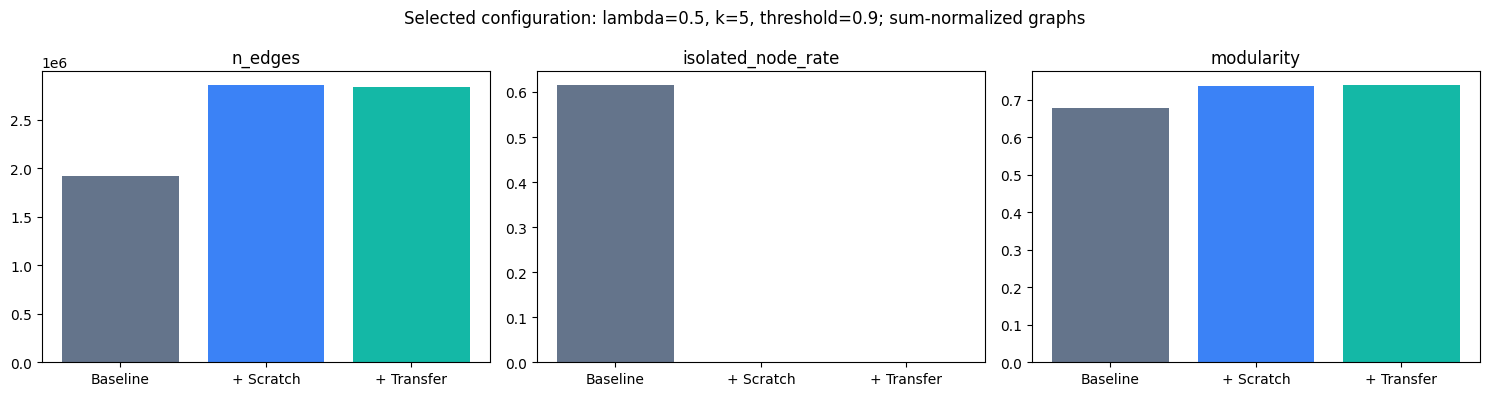

SAVED /content/drive/MyDrive/Colab Notebooks/E3_proposed_outputs/selected_run/E3_PROPOSED_RESULTS.md


,method,n_nodes,n_active_nodes,n_edges,isolated_node_rate,largest_component_nodes,n_communities,modularity
0,baseline_delivered,224685,86488,1922134,0.615070,81055,2127,0.679030
1,baseline_plus_scratch,224685,224640,2853967,0.000200,220826,742,0.736721
2,baseline_plus_transfer,224685,224639,2834812,0.000205,220417,698,0.739346


In [ ]:
# E3-N5 — Xuất báo cáo sau khi hai graph cấu hình đã chọn chạy xong
import matplotlib.pyplot as plt
assert len(rows)==3, "Chưa đủ hai graph tăng cường hoàn tất; không xuất kết quả giả."
comparison=pd.DataFrame(rows)
comparison.to_csv(OUT/"e3_proposed_comparison.csv",index=False)
columns=["method","n_nodes","n_active_nodes","n_edges","isolated_node_rate","largest_component_nodes","n_communities","modularity"]
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,col in zip(axes,["n_edges","isolated_node_rate","modularity"]):
    ax.bar(["Baseline","+ Scratch","+ Transfer"],comparison[col],color=["#64748b","#3b82f6","#14b8a6"]); ax.set_title(col)
fig.suptitle(f"Selected configuration: lambda={CFG['lambda']}, k={CFG['top_k']}, threshold={CFG['cosine_threshold']}; sum-normalized graphs")
fig.tight_layout(); fig.savefig(OUT/"e3_proposed_comparison.png",dpi=180); plt.show()
def file_hash(path):
    h=hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda:f.read(1024*1024),b""): h.update(chunk)
    return h.hexdigest()
source_files=[BASE/"combined/edges.csv",BASE/"combined/nodes.csv",BASE/"combined/config.json",E1/"preprocessing/tfidf_vectorizer.joblib",E2/"artifacts/e2_scratch_model.pt",E2/"artifacts/e2_transfer_model.pt"]
run_config={"config":CFG,"reproduction":reproduction,"baseline_prior_reproduction_ari":1.0,"input_sha256":{str(p):file_hash(p) for p in source_files},"packages":{p:metadata.version(p) for p in ["numpy","pandas","torch","scipy","scikit-learn","faiss-cpu","igraph","leidenalg"]}}
(OUT/"run_config.json").write_text(json.dumps(run_config,ensure_ascii=False,indent=2))
report_parts=[
"## Backend CPU",
"Dùng igraph + leidenalg, RBConfigurationVertexPartition, seed=42, resolution=1, n_iterations=-1 theo người 4. Không dùng cuGraph. Output cấu hình đã chọn lưu ở results/.",
"# E3_PROPOSED_RESULTS — Người 5",
"## Cấu hình đã chọn và lý do",
decision_text,
"## Kết quả graph chính",
comparison[columns].to_markdown(index=False),
"## Thay đổi cấu trúc",
comparison[["method","n_edges_added","n_edges_removed","similarity_baseline_overlap","active_partition_ari_vs_baseline"]].to_markdown(index=False),
"## Audit similarity/ANN full corpus",
pd.DataFrame(ann_audits).to_markdown(index=False),
"## Provenance và giới hạn",
"Embedding tái tạo bằng checkpoint E2 và TF-IDF E1, đối chiếu khớp toàn bộ 44.938 embedding Test của người 3. Baseline CPU đã được tái tạo khớp bản bàn giao: ARI=1 và modularity khác khoảng 1e-11. Giữ bản bàn giao làm đối chứng CPU, không chạy lại phép kiểm tra dài này.",
"Account representation học từ nội dung TF-IDF qua MLP, chưa gồm toàn bộ hành vi thời gian/hành động. Giữ mọi node; account TF-IDF rỗng không tạo similarity từ bias-only embedding. Full corpus gồm Train accounts của E2 nên đây là mô tả/transductive, không phải held-out campaign detection.",
"Không dùng Bad/Good để tạo cạnh/chọn tham số. Modularity hay nhiều cạnh hơn không chứng minh phát hiện campaign tốt hơn. Chưa có edge-count control hoặc lambda sensitivity; không kết luận Transfer vượt Scratch chỉ từ graph metrics.",
"E2: code Good=1 nhưng pos_weight=n_Good/n_Bad đang tăng trọng số Good; người 3 cần xác minh. Code bàn giao train 10 epoch, chưa thể hiện validation checkpoint selection. Giữ nguyên checkpoint, không âm thầm sửa.",
"## Output",
"Embeddings và account IDs ở thư mục cha. parameter_selection/ lưu toàn bộ bước chọn tham số. results/ lưu similarity graphs, enhanced graphs, node/community assignments, metrics, bảng/hình so sánh và run_config.json."
]
report=(chr(10)*2).join(report_parts)
(OUT/"E3_PROPOSED_RESULTS.md").write_text(report,encoding="utf-8")
print("SAVED",OUT/"E3_PROPOSED_RESULTS.md")
display(comparison[columns])


In [17]:
# E3-N5 — Phân tích mức hoạt động hậu nghiệm, không dùng để chọn cạnh
from collections import Counter
from scipy.stats import spearmanr
activity=Counter()
for p in [DATA/"honduras_bad_normalized.jsonl",DATA/"honduras_good_normalized.jsonl"]:
    with p.open(encoding="utf-8") as f:
        for line in f:
            if line.strip(): activity[str(json.loads(line)["account_id"])]+=1
counts=np.array([activity[u] for u in ids_all]); assert (counts>0).all()
cutoff=float(np.quantile(counts,0.9)); high=counts>=cutoff
activity_rows=[]
for name in ["baseline_delivered","baseline_plus_scratch","baseline_plus_transfer"]:
    table=pd.read_csv(OUT/name/"nodes.csv",dtype={"account_id":str})
    assert table.account_id.tolist()==ids_all.tolist()
    deg=table.degree.to_numpy(); strength=table.strength.to_numpy()
    activity_rows.append({"method":name,"activity_source":"all normalized records incl. duplicates, descriptive only","spearman_tweet_count_degree":float(spearmanr(counts,deg).statistic),"spearman_tweet_count_strength":float(spearmanr(counts,strength).statistic),"high_activity_cutoff":cutoff,"high_activity_account_fraction":float(high.mean()),"high_activity_degree_share":float(deg[high].sum()/deg.sum()),"high_activity_strength_share":float(strength[high].sum()/strength.sum()),"degree_top1pct_share":float(np.sort(deg)[-max(1,len(deg)//100):].sum()/deg.sum())})
activity_df=pd.DataFrame(activity_rows); activity_df.to_csv(OUT/"activity_level_analysis.csv",index=False)
pd.DataFrame({"account_id":ids_all,"normalized_record_count":counts}).to_csv(OUT/"account_activity.csv",index=False)
activity_section="\n\n## Activity-level analysis (hậu nghiệm)\n"+activity_df.to_markdown(index=False)+"\nActivity = số record trong normalized corpus trước conflict/dedup filtering, không phải số event độc lập. Nhóm >= phân vị 90 có thể chiếm hơn 10% node do ties. Correlation/degree concentration không chứng minh nguyên nhân.\n"
report_path=OUT/"E3_PROPOSED_RESULTS.md"
text=report_path.read_text().replace("và activity-level analysis. Người 6", ". Activity-level analysis có ở phần cuối. Người 6")
report_path.write_text(text+activity_section,encoding="utf-8")
display(activity_df)
print("DONE",OUT)

,method,activity_source,spearman_tweet_count_degree,spearman_tweet_count_strength,high_activity_cutoff,high_activity_account_fraction,high_activity_degree_share,high_activity_strength_share,degree_top1pct_share
0,baseline_delivered,"all normalized records incl. duplicates, descr...",0.529802,0.532935,9.0,0.103977,0.637197,0.692162,0.296360
1,baseline_plus_scratch,"all normalized records incl. duplicates, descr...",0.553621,0.508507,9.0,0.103977,0.462845,0.398396,0.222750
2,baseline_plus_transfer,"all normalized records incl. duplicates, descr...",0.547711,0.498557,9.0,0.103977,0.463838,0.395966,0.224773


DONE /content/drive/MyDrive/Colab Notebooks/E3_proposed_outputs/selected_run


In [18]:
# Kiểm tra backend CPU, không chạy lại graph đầy đủ
import igraph as ig, leidenalg
g=ig.Graph(n=6,edges=[(0,1),(0,2),(1,2),(3,4),(3,5),(4,5)])
g.es["weight"]=[1.0]*6
p=leidenalg.find_partition(g,leidenalg.RBConfigurationVertexPartition,weights="weight",resolution_parameter=1.0,n_iterations=-1,seed=42)
assert len(p)==2 and abs(g.modularity(p.membership,weights="weight")-0.5)<1e-10
print("PASS CPU: igraph + leidenalg; RBConfiguration; seed=42; resolution=1; iterations=-1.")

PASS CPU: igraph + leidenalg; RBConfiguration; seed=42; resolution=1; iterations=-1.
